### Escuela Politecnica Nacional

**Facultad de Ingeniería de Sistemas**

|Campo | Información |
| :--- | :--- |
| **Nombre:** | Michael Yánez |
| **Asignatura:** | Recuperación de la Información |
| **Docente:** | Ing. Ivan Carrera PhD |

**02 Procesamiento de texto, recuperación secuencial e indexación**

Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

**Parte A. Corpus Pequeño**

1. Preparación del corpus

A continuacións se carga los 18 documentos de Gutenberg, y se explora sus dimensiones básicas como tamaño en caracteres y palabras.

In [1]:
import re
import nltk
import pandas as pd
from IPython.display import display

nltk.download('gutenberg', quiet=True)
from nltk.corpus import gutenberg

file_ids = gutenberg.fileids()
print(f"Número total de documentos: {len(file_ids)}\n")

doc_stats = []
for file_id in file_ids:
    raw_text = gutenberg.raw(file_id)
    raw_words = gutenberg.words(file_id)
    doc_stats.append({
        "ID Documento": file_id,
        "Caracteres": len(raw_text),
        "Palabras sin procesar": len(raw_words)
    })

df_stats = pd.DataFrame(doc_stats)
display(df_stats)

def preprocess_text(text: str) -> list[str]:
    return re.findall(r'\b\w+\b', text.lower())

corpus_preprocessed = {}
for file_id in file_ids:
    raw_text = gutenberg.raw(file_id)
    corpus_preprocessed[file_id] = preprocess_text(raw_text)

primer_doc = file_ids[0]
print(f"\n--- Muestra de tokens normalizados para '{primer_doc}' ---")
print(corpus_preprocessed[primer_doc][:15])

Número total de documentos: 18



,ID Documento,Caracteres,Palabras sin procesar
0,austen-emma.txt,887071,192427
1,austen-persuasion.txt,466292,98171
2,austen-sense.txt,673022,141576
3,bible-kjv.txt,4332554,1010654
4,blake-poems.txt,38153,8354
5,bryant-stories.txt,249439,55563
6,burgess-busterbrown.txt,84663,18963
7,carroll-alice.txt,144395,34110
8,chesterton-ball.txt,457450,96996
9,chesterton-brown.txt,406629,86063



--- Muestra de tokens normalizados para 'austen-emma.txt' ---
['emma', 'by', 'jane', 'austen', '1816', 'volume', 'i', 'chapter', 'i', 'emma', 'woodhouse', 'handsome', 'clever', 'and', 'rich']


2. Búsqueda secuencial

Se implementa un función que reciba un termino de consulta y devuelva los identificadores de todos los documentos que lo contienen

In [2]:
def sequential_search(term: str, corpus: dict[str, list[str]]) -> list[str]:

    term_normalized = term.lower().strip()
    matching_docs = []

    for doc_id, tokens in corpus.items():
        for token in tokens:
            if token == term_normalized:
                matching_docs.append(doc_id)
                break 
    return matching_docs

test_terms = [
    ("Frecuente", "the"),
    ("Poco Frecuente", "romeo"),
    ("Inexistente", "cyberpunk")
]

search_results = []
for category, term in test_terms:
    results = sequential_search(term, corpus_preprocessed)
    search_results.append({
        "Categoría": category,
        "Término Buscado": term,
        "Cantidad de Documentos Encontrados": len(results),
        "Documentos Coincidentes": results
    })

df_results = pd.DataFrame(search_results)
display(df_results)

,Categoría,Término Buscado,Cantidad de Documentos Encontrados,Documentos Coincidentes
0,Frecuente,the,18,"[austen-emma.txt, austen-persuasion.txt, auste..."
1,Poco Frecuente,romeo,1,[chesterton-brown.txt]
2,Inexistente,cyberpunk,0,[]


3. Medición de tiempos de ejecución

En este paso mediremos la velocidad de la búsqueda secuencial para los mismo términos del paso anterior

In [3]:
import time

NUM_RUNS = 30
timing_results = []

for category, term in test_terms:
    execution_times_ns = []
    
    for _ in range(NUM_RUNS):
        start_time = time.perf_counter_ns()
        _ = sequential_search(term, corpus_preprocessed)
        end_time = time.perf_counter_ns()
        
        execution_times_ns.append(end_time - start_time)
    
    mean_time_ns = sum(execution_times_ns) / NUM_RUNS
    mean_time_ms = mean_time_ns / 1_000_000
    
    timing_results.append({
        "Categoría": category,
        "Término": term,
        "Ejecuciones": NUM_RUNS,
        "Tiempo Medio (ms)": round(mean_time_ms, 4)
    })

df_timings = pd.DataFrame(timing_results)
display(df_timings)

,Categoría,Término,Ejecuciones,Tiempo Medio (ms)
0,Frecuente,the,30,0.0067
1,Poco Frecuente,romeo,30,35.7868
2,Inexistente,cyberpunk,30,33.0096


4. Construcción del índice invertido

Esta estructura de datos permite mapear cada término del vocabulario a la lista de documentos en los que aparece  el término.

In [4]:
class InvertedIndex:
    def __init__(self, corpus: dict[str, list[str]]):
        self.all_docs = set(corpus.keys())
        self.index = {}
        self._build_index(corpus)

    def _build_index(self, corpus: dict[str, list[str]]):
        """Construye el índice invertido mapeando términos a conjuntos de doc_ids."""
        for doc_id, tokens in corpus.items():
            for token in tokens:
                if token not in self.index:
                    self.index[token] = set()
                self.index[token].add(doc_id)

    def get_postings(self, term: str) -> set[str]:
        """Devuelve la lista de postings (conjunto de doc_ids) de un término."""
        return self.index.get(term.lower().strip(), set())

    def get_document_frequency(self, term: str) -> int:
        """Devuelve la Frecuencia Documental (DF) de un término."""
        return len(self.get_postings(term))

    def query_single(self, term: str) -> set[str]:
        """Consulta de un solo término."""
        return self.get_postings(term)

    def query_and(self, term1: str, term2: str) -> set[str]:
        """Consulta booleana AND (Intersección)."""
        return self.get_postings(term1) & self.get_postings(term2)

    def query_or(self, term1: str, term2: str) -> set[str]:
        """Consulta booleana OR (Unión)."""
        return self.get_postings(term1) | self.get_postings(term2)

    def query_not(self, term: str) -> set[str]:
        """Consulta booleana NOT (Complemento respecto al corpus completo)."""
        return self.all_docs - self.get_postings(term)


inverted_index = InvertedIndex(corpus_preprocessed)

print(f"Tamaño del vocabulario construido: {len(inverted_index.index)} términos únicos.\n")

sample_terms = ["the", "romeo", "cyberpunk", "monster", "love"]
df_inspection = []

for term in sample_terms:
    postings = sorted(list(inverted_index.get_postings(term)))
    df_val = inverted_index.get_document_frequency(term)
    df_inspection.append({
        "Término": term,
        "Frecuencia Documental (DF)": df_val,
        "Muestra de Postings": postings[:3] if postings else "Ninguno"
    })

print("--- Inspección de Postings y Frecuencia Documental (DF) ---")
display(pd.DataFrame(df_inspection))

bool_queries = [
    ("Un solo término ('romeo')", sorted(list(inverted_index.query_single("romeo")))),
    ("AND ('romeo' AND 'love')", sorted(list(inverted_index.query_and("romeo", "love")))),
    ("OR ('juliet' OR 'monster')", sorted(list(inverted_index.query_or("juliet", "monster")))),
    ("NOT (NOT 'the')", sorted(list(inverted_index.query_not("the"))))
]

query_results = []
for desc, res in bool_queries:
    query_results.append({
        "Tipo de Consulta": desc,
        "Cantidad de Docs": len(res),
        "Documentos Encontrados": res
    })

print("\n--- Resultados de Consultas Booleanas ---")
display(pd.DataFrame(query_results))

Tamaño del vocabulario construido: 42099 términos únicos.

--- Inspección de Postings y Frecuencia Documental (DF) ---


,Término,Frecuencia Documental (DF),Muestra de Postings
0,the,18,"[austen-emma.txt, austen-persuasion.txt, auste..."
1,romeo,1,[chesterton-brown.txt]
2,cyberpunk,0,Ninguno
3,monster,6,"[bryant-stories.txt, chesterton-ball.txt, ches..."
4,love,15,"[austen-emma.txt, austen-persuasion.txt, auste..."



--- Resultados de Consultas Booleanas ---


,Tipo de Consulta,Cantidad de Docs,Documentos Encontrados
0,Un solo término ('romeo'),1,[chesterton-brown.txt]
1,AND ('romeo' AND 'love'),1,[chesterton-brown.txt]
2,OR ('juliet' OR 'monster'),6,"[bryant-stories.txt, chesterton-ball.txt, ches..."
3,NOT (NOT 'the'),0,[]


5. Comparación

In [5]:
NUM_RUNS = 30
comparison_results = []

for category, term in test_terms:
    times_seq_ns = []
    for _ in range(NUM_RUNS):
        start = time.perf_counter_ns()
        res_seq = sequential_search(term, corpus_preprocessed)
        end = time.perf_counter_ns()
        times_seq_ns.append(end - start)

    mean_seq_ms = (sum(times_seq_ns)/NUM_RUNS)/1_000_000

    times_idx_ns = []
    for _ in range(NUM_RUNS):
        start = time.perf_counter_ns()
        res_idx = inverted_index.query_single(term)
        end = time.perf_counter_ns()
        times_idx_ns.append(end -start)

    mean_idx_ms = (sum(times_idx_ns)/ NUM_RUNS)/1_000_000

    seq_set = set(res_seq)
    idx_set = set(res_idx)
    are_identical = (seq_set == idx_set)

    speedup = mean_seq_ms /mean_idx_ms if mean_idx_ms > 0 else 0

    comparison_results.append({
        "Categoría": category,
        "Término": term,
        "¿Resultados identicos?": are_identical,
        "Tiempo secuencial (ms)": round(mean_seq_ms, 5),
        "Tiempo índice (ms)": round(mean_idx_ms, 5),
        "Aceleración (speedup)": f"{round(speedup, 1)}x"
    })

df_comparison = pd.DataFrame(comparison_results)
display(df_comparison)


,Categoría,Término,¿Resultados identicos?,Tiempo secuencial (ms),Tiempo índice (ms),Aceleración (speedup)
0,Frecuente,the,True,0.00548,0.00046,11.8x
1,Poco Frecuente,romeo,True,34.28707,0.00071,48066.0x
2,Inexistente,cyberpunk,True,32.15997,0.00060,53303.8x


**Parte B. Corpus grande**

6. Descarga de Gutenberg

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [6]:
import zipfile
import tarfile
import os

zip_path = "txt-files.tar.zip"

pattern = re.compile(r'(\d+)(?:-[a-zA-Z0-9]+)?\.txt$')

valid_book_ids = set()

if not os.path.exists(zip_path):
    print(f" Archivo '{zip_path}' no encontrado en el directorio actual.")
    print("Asegúrate de descargarlo antes de ejecutar esta celda.")
else:
    print(f"Analizando '{zip_path}' en memoria (esto puede tomar varios minutos)...")
    
    with zipfile.ZipFile(zip_path, 'r') as z:
        tar_filename = [name for name in z.namelist() if name.endswith('.tar')][0]
        
        with z.open(tar_filename) as tar_extracted:
            with tarfile.open(fileobj=tar_extracted, mode='r|') as tar:
                for tarinfo in tar:
                    if tarinfo.isfile() and tarinfo.name.endswith('.txt'):
                        match = pattern.search(tarinfo.name)
                        if match:
                            book_id = match.group(1)
                            valid_book_ids.add(book_id)

    print(f"\n Análisis completado.")
    print(f"Cantidad de documentos válidos (libros únicos identificados): {len(valid_book_ids)}")

Analizando 'txt-files.tar.zip' en memoria (esto puede tomar varios minutos)...

 Análisis completado.
Cantidad de documentos válidos (libros únicos identificados): 78145


7. Recuperación sobre el corpus grande

Reutilice las funciones desarrolladas en la Parte A.

Procese los documentos con la misma configuración de normalización.
Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
Construya el índice invertido.
Repita las consultas utilizando el índice.
Compruebe la igualdad de resultados y compare los tiempos.

In [7]:
import sys

zip_path = "txt-files.tar.zip"
import re
pattern = re.compile(r'(\d+)(?:-[a-zA-Z0-9]+)?\.txt$')

def load_gutenberg_subset(zip_file_path: str, max_docs: int) -> dict[str, list[str]]:
    """
    Extrae, decodifica y preprocesa un máximo de max_docs libros únicos 
    directamente desde el archivo comprimido.
    """
    subset_corpus = {}
    loaded_ids = set()
    
    print(f"Extrayendo y procesando {max_docs} documentos de {zip_file_path}...")
    
    with zipfile.ZipFile(zip_file_path, 'r') as z:
        tar_filename = [name for name in z.namelist() if name.endswith('.tar')][0]
        with z.open(tar_filename) as tar_extracted:
            with tarfile.open(fileobj=tar_extracted, mode='r|') as tar:
                for tarinfo in tar:
                    if len(loaded_ids) >= max_docs:
                        break
                        
                    if tarinfo.isfile() and tarinfo.name.endswith('.txt'):
                        match = pattern.search(tarinfo.name)
                        if match:
                            book_id = match.group(1)
                            
                            if book_id not in loaded_ids:
                                f = tar.extractfile(tarinfo)
                                if f:
                                    try:
                                        raw_text = f.read().decode('utf-8', errors='ignore')
                                        subset_corpus[book_id] = preprocess_text(raw_text)
                                        loaded_ids.add(book_id)
                                    except Exception as e:
                                        continue
                                        
    print(f"Extraccion finalizada: {len(subset_corpus)} documentos procesados.")
    return subset_corpus

N_DOCS = 50
large_corpus_subset = load_gutenberg_subset(zip_path, N_DOCS)

memory_bytes = sys.getsizeof(large_corpus_subset) + sum(sys.getsizeof(v) for v in large_corpus_subset.values())
print(f"Memoria RAM estimada para {N_DOCS} documentos preprocesados: {memory_bytes / (1024*1024):.2f} MB\n")

print("Construyendo el indice invertido para el subconjunto...")
subset_index = InvertedIndex(large_corpus_subset)

test_terms_b = ["man", "science", "cyberpunk"]
NUM_RUNS_B = 10 
comparison_b = []

print("Iniciando pruebas de rendimiento (10 ejecuciones por termino)...")

for term in test_terms_b:
    times_seq = []
    for _ in range(NUM_RUNS_B):
        start = time.perf_counter_ns()
        res_seq = sequential_search(term, large_corpus_subset)
        end = time.perf_counter_ns()
        times_seq.append(end - start)
    mean_seq_ms = (sum(times_seq) / NUM_RUNS_B) / 1_000_000

    times_idx = []
    for _ in range(NUM_RUNS_B):
        start = time.perf_counter_ns()
        res_idx = subset_index.query_single(term)
        end = time.perf_counter_ns()
        times_idx.append(end - start)
    mean_idx_ms = (sum(times_idx) / NUM_RUNS_B) / 1_000_000

    are_identical = (set(res_seq) == set(res_idx))
    speedup = mean_seq_ms / mean_idx_ms if mean_idx_ms > 0 else 0

    comparison_b.append({
        "Término": term,
        "¿Resultados Idénticos?": are_identical,
        "T. Secuencial (ms)": round(mean_seq_ms, 2),
        "T. Índice (ms)": round(mean_idx_ms, 5),
        "Aceleración": f"{round(speedup, 1)}x"
    })

display(pd.DataFrame(comparison_b))

Extrayendo y procesando 50 documentos de txt-files.tar.zip...
Extraccion finalizada: 50 documentos procesados.
Memoria RAM estimada para 50 documentos preprocesados: 19.60 MB

Construyendo el indice invertido para el subconjunto...
Iniciando pruebas de rendimiento (10 ejecuciones por termino)...


,Término,¿Resultados Idénticos?,T. Secuencial (ms),T. Índice (ms),Aceleración
0,man,True,1.36,0.00125,1087.0x
1,science,True,21.59,0.00120,17993.8x
2,cyberpunk,True,43.52,0.00139,31307.5x


Parte C. Análisis experimental de escalabilidad

8. Tiempo de ejecución en función del corpus

En esta sección evaluaremos cómo escala el tiempo de respuesta de ambos algoritmos a medida que el tamaño de la colección crece. Utilizaremos los tamaños sugeridos de 50, 100, 250, 500 y 1.000 documentos

Extrayendo el corpus base de 1000 documentos...
Extrayendo y procesando 1000 documentos de txt-files.tar.zip...
Extraccion finalizada: 1000 documentos procesados.
Extraccion completada. Iniciando experimento...
Evaluando subconjunto con n=50 documentos...
Evaluando subconjunto con n=100 documentos...
Evaluando subconjunto con n=250 documentos...
Evaluando subconjunto con n=500 documentos...
Evaluando subconjunto con n=1000 documentos...


,n_docs,tokens,t_secuencial,t_indice
0,50,2416148,30.464657,0.035783
1,100,5787336,64.443567,0.001237
2,250,18794756,156.957293,0.001133
3,500,35944391,310.776777,0.001543
4,1000,73325886,610.771780,0.001263


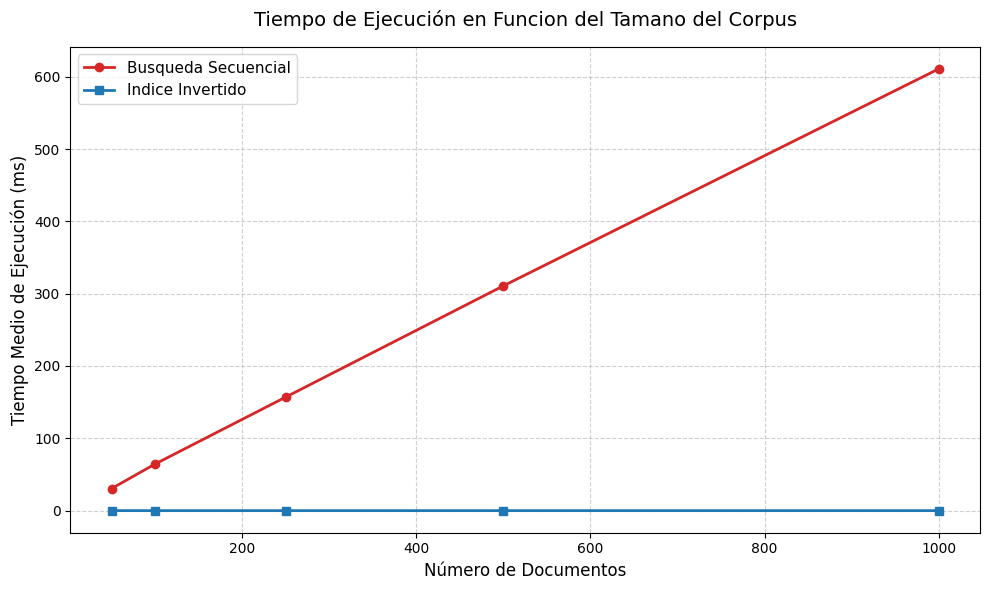

In [9]:
import matplotlib.pyplot as plt

corpus_sizes = [50, 100, 250, 500, 1000]
max_docs = max(corpus_sizes)

print(f"Extrayendo el corpus base de {max_docs} documentos...")
large_corpus_base = load_gutenberg_subset(zip_path, max_docs)
print("Extraccion completada. Iniciando experimento...")

term_to_search = "science"
NUM_RUNS_C = 30
experiment_results = []

for n in corpus_sizes:
    print(f"Evaluando subconjunto con n={n} documentos...")
    
    subset_items = list(large_corpus_base.items())[:n]
    subset = dict(subset_items)
    
    total_tokens = sum(len(tokens) for tokens in subset.values())
    
    times_seq = []
    for _ in range(NUM_RUNS_C):
        start = time.perf_counter_ns()
        _ = sequential_search(term_to_search, subset)
        end = time.perf_counter_ns()
        times_seq.append(end - start)
    mean_seq_ms = (sum(times_seq) / NUM_RUNS_C) / 1_000_000
    
    subset_index = InvertedIndex(subset)
    
    times_idx = []
    for _ in range(NUM_RUNS_C):
        start = time.perf_counter_ns()
        _ = subset_index.query_single(term_to_search)
        end = time.perf_counter_ns()
        times_idx.append(end - start)
    mean_idx_ms = (sum(times_idx) / NUM_RUNS_C) / 1_000_000
    
    experiment_results.append({
        "n_docs": n,
        "tokens": total_tokens,
        "t_secuencial": mean_seq_ms,
        "t_indice": mean_idx_ms
    })

df_experiment = pd.DataFrame(experiment_results)
display(df_experiment)

plt.figure(figsize=(10, 6))

plt.plot(df_experiment["n_docs"], df_experiment["t_secuencial"], 
         marker='o', linestyle='-', color='#d62728', label="Busqueda Secuencial", linewidth=2)
plt.plot(df_experiment["n_docs"], df_experiment["t_indice"], 
         marker='s', linestyle='-', color='#1f77b4', label="Indice Invertido", linewidth=2)

plt.title("Tiempo de Ejecución en Funcion del Tamano del Corpus", fontsize=14, pad=15)
plt.xlabel("Número de Documentos", fontsize=12)
plt.ylabel("Tiempo Medio de Ejecución (ms)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

9. Estimación de una función de tiempo

Vamos a demostrar matemáticamente lo que acabamos de ver en la gráfica, calculando la ecuación de la recta $t(n) = an + b$ mediante regresión lineal y obteniendo el coeficiente $R^2$

--- Modelos de Estimación de Tiempo t(n) = a*n + b ---
Búsqueda Secuencial: t(n) = 0.6094n + 3.1098  (R^2 = 0.9999)
Índice Invertido:    t(n) = -0.000019n + 0.015334  (R^2 = 0.2238)



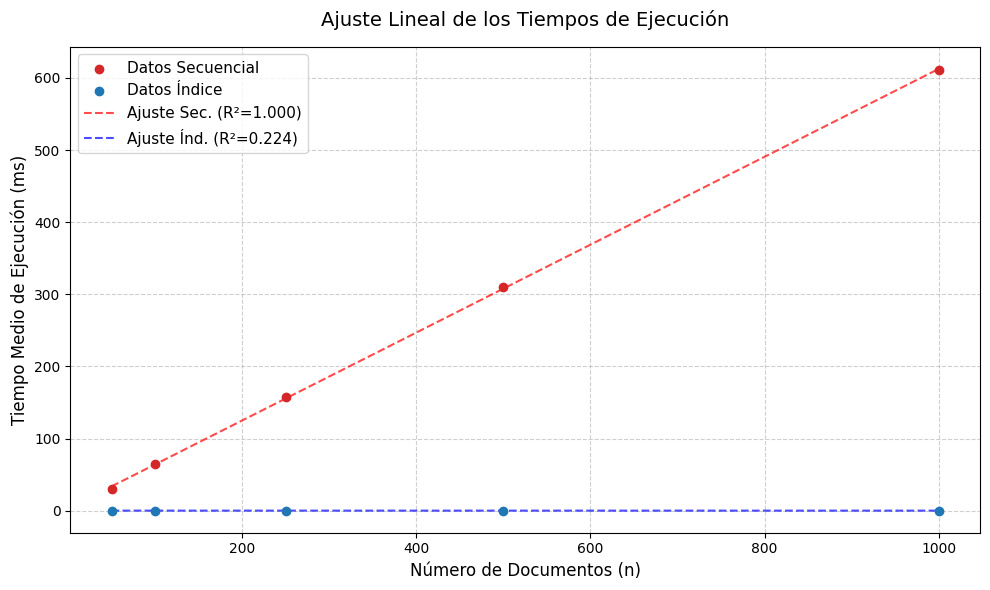

In [10]:
import numpy as np
from sklearn.metrics import r2_score

x = df_experiment["n_docs"].values
y_seq = df_experiment["t_secuencial"].values
y_idx = df_experiment["t_indice"].values

coef_seq = np.polyfit(x, y_seq, 1)
a_seq, b_seq = coef_seq
y_seq_pred = a_seq * x + b_seq
r2_seq = r2_score(y_seq, y_seq_pred)

coef_idx = np.polyfit(x, y_idx, 1)
a_idx, b_idx = coef_idx
y_idx_pred = a_idx * x + b_idx
r2_idx = r2_score(y_idx, y_idx_pred)

print("--- Modelos de Estimación de Tiempo t(n) = a*n + b ---")
print(f"Búsqueda Secuencial: t(n) = {a_seq:.4f}n + {b_seq:.4f}  (R^2 = {r2_seq:.4f})")
print(f"Índice Invertido:    t(n) = {a_idx:.6f}n + {b_idx:.6f}  (R^2 = {r2_idx:.4f})\n")

plt.figure(figsize=(10, 6))

plt.scatter(x, y_seq, color='#d62728', label='Datos Secuencial', zorder=5)
plt.scatter(x, y_idx, color='#1f77b4', label='Datos Índice', zorder=5)

plt.plot(x, y_seq_pred, color='red', linestyle='--', alpha=0.7, 
         label=f'Ajuste Sec. (R²={r2_seq:.3f})')
plt.plot(x, y_idx_pred, color='blue', linestyle='--', alpha=0.7, 
         label=f'Ajuste Índ. (R²={r2_idx:.3f})')

plt.title("Ajuste Lineal de los Tiempos de Ejecución", fontsize=14, pad=15)
plt.xlabel("Número de Documentos (n)", fontsize=12)
plt.ylabel("Tiempo Medio de Ejecución (ms)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Declaración de uso de IA generativa**

Para el desarrollo de esta tarea se uso IA el la cuestión revisón de código y correción sintáctica.